# 8 · Monitoring & improvement

| | |
|---|---|
| Lifecycle stage | 8 of 8: *Monitoring & improvement* (track performance, detect drift, retrain) |
| Tools | Evidently AI, Prometheus, Grafana, MLflow |
| Code | `monitor.py`, `drift.py`, `tracking.py`, `api.py` (`/metrics`, `/feedback`), `platform/prometheus`, `platform/grafana` |
| Outputs | `reports/monitoring/summary.json`, `monthly.csv`, `feature_drift.csv`, Evidently HTML report per month, MLflow monitoring run |

Monitoring replays the validation and test periods **month by month as if the model were live** and asks:

1. **Data drift**: has the input distribution moved away from the training data? (Evidently `DataDriftPreset`,
   with the project's own PSI as a cross-check)
2. **Performance**: at the fixed threshold, are recall, precision and alert volume still acceptable?
   (in production the labels arrive later, from chargebacks and analyst feedback via `/feedback`)

A **retraining recommendation** is raised when more than 30% of monitored features drift, recall falls below
0.85 or precision below 0.40 (`config/pipeline.yaml → monitoring`).

In [1]:
import os, sys, json, warnings
from pathlib import Path
ROOT = Path(os.environ.get("FRAUDLENS_ROOT") or (Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())).resolve()
CODE = Path(os.environ.get("FRAUDLENS_CODE", ROOT)).resolve()
sys.path.insert(0, str(CODE / "src"))
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

from fraudlens import viz
from fraudlens.utils import load_config, read_json, read_table

viz.setup()
import plotly.io as pio
pio.renderers.default = "plotly_mimetype+notebook_connected"   # small notebooks: plotly.js from the CDN
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 170)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
cfg = load_config(root=ROOT)
P = cfg["paths"]
print(f"Project root: {ROOT.name} | data present: {(P['silver'] / 'transactions.parquet').exists()}")
from fraudlens import monitor
from fraudlens.drift import psi
summ = read_json(P["monitoring"] / "summary.json")
monthly = pd.DataFrame(summ["monthly"])
print(f"drift engine: {summ['drift_engine']}; reference: {summ['reference']}; policy: {summ['policy']}")

Project root: fraudlens | data present: True


drift engine: Evidently DataDriftPreset + PSI cross-check; reference: training period (100,000-row sample); policy: {'drift_share_alert': 0.3, 'recall_floor': 0.85, 'precision_floor': 0.4}


## 8.1 Month by month: drift and performance

In [2]:
cols = ["month", "transactions", "frauds", "evidently_drift_share", "psi_major_share", "pr_auc", "recall",
        "precision", "alerts_per_day", "net_benefit", "retrain_recommended", "reasons"]
monthly[cols]

,month,transactions,frauds,evidently_drift_share,psi_major_share,pr_auc,recall,precision,alerts_per_day,net_benefit,retrain_recommended,reasons
0,2020-05,53834,335,0.1429,0.0000,0.9884,0.9881,0.7680,20.1000,"158,328.3900",False,
1,2020-06,87805,467,0.2857,0.0000,0.9760,0.9700,0.7770,19.4000,"217,276.7600",False,
2,2020-07,85848,321,0.2857,0.0000,0.9589,0.9439,0.7146,13.7000,"135,548.1800",False,
3,2020-08,88759,415,0.3571,0.0000,0.9744,0.9687,0.7556,17.2000,"176,447.3400",True,36% of monitored features drifted
4,2020-09,69533,340,0.1429,0.0000,0.9735,0.9588,0.7376,14.7000,"171,242.9700",False,
5,2020-10,69348,384,0.2857,0.0000,0.9757,0.9661,0.7260,16.5000,"167,446.3300",False,
6,2020-11,72635,294,0.2143,0.0000,0.9736,0.9796,0.7129,13.5000,"131,617.7400",False,
7,2020-12,139538,258,0.5000,0.3080,0.9553,0.9496,0.6712,11.8000,"119,069.3600",True,50% of monitored features drifted


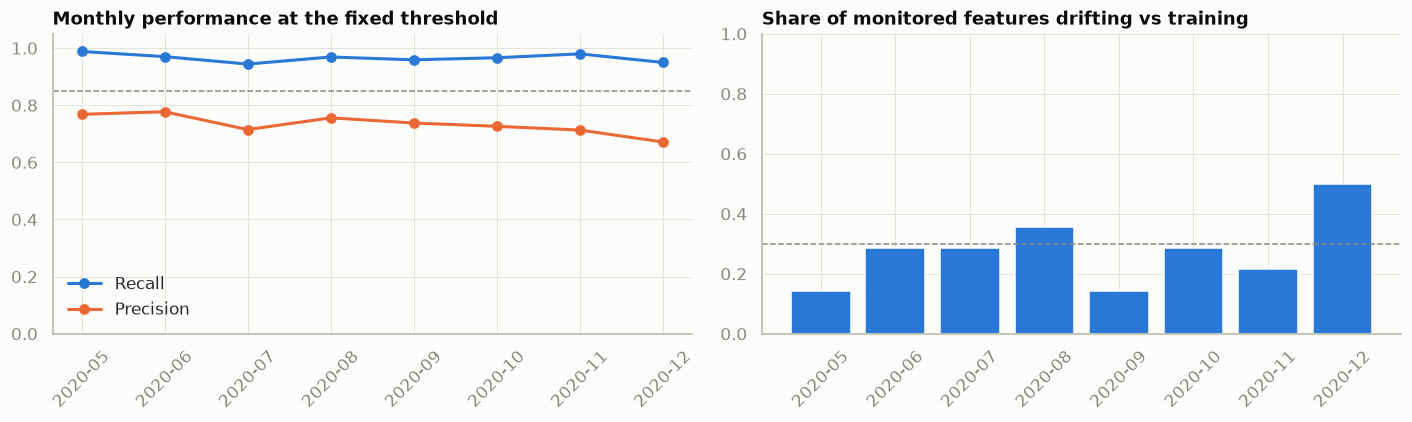

In [3]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
fig = make_subplots(rows=1, cols=2, subplot_titles=("Performance at the fixed threshold", "Share of monitored features drifting"))
fig.add_trace(go.Scatter(x=monthly["month"], y=monthly["recall"], name="recall", mode="lines+markers", line_color=viz.SERIES[0]), 1, 1)
fig.add_trace(go.Scatter(x=monthly["month"], y=monthly["precision"], name="precision", mode="lines+markers", line_color=viz.SERIES[1]), 1, 1)
fig.add_hline(y=summ["policy"]["recall_floor"], line_dash="dash", line_color=viz.MUTED, row=1, col=1)
share = monthly["evidently_drift_share"].fillna(monthly["psi_major_share"])
fig.add_trace(go.Bar(x=monthly["month"], y=share, name="drift share",
                     marker_color=[viz.STATUS["missed"] if r else viz.SERIES[0] for r in monthly["retrain_recommended"]]), 1, 2)
fig.add_hline(y=summ["policy"]["drift_share_alert"], line_dash="dash", line_color=viz.MUTED, row=1, col=2)
fig.update_layout(template=viz.plotly_template(), height=380, yaxis_range=[0, 1.05])
fig.show()
if (P["figures"] / "19_monitoring_monthly.png").exists():
    display(Image(filename=str(P["figures"] / "19_monitoring_monthly.png"), width=800))

### 8.1.1 Is the monthly performance stable, or just noisy?

Each month has only 130 to 400 frauds, so a monthly recall is itself uncertain. `fraudlens.stability` adds a
Wilson 95% interval to every month, checks each month against the policy floors, and tests with a chi-square
test whether the months differ more than chance would allow.

In [4]:
from fraudlens.stability import run_stability
stab = run_stability(cfg)
m = pd.DataFrame(stab["monthly"]["months"])
fig = go.Figure()
for name, col, color in [("recall", "recall", viz.SERIES[0]), ("precision", "precision", viz.SERIES[1])]:
    ci = np.array(m[f"{col}_ci95"].tolist())
    fig.add_trace(go.Scatter(x=m["month"], y=m[col], name=name, mode="lines+markers", line_color=color,
                             error_y=dict(type="data", symmetric=False, array=ci[:, 1] - m[col], arrayminus=m[col] - ci[:, 0])))
fig.add_hline(y=summ["policy"]["recall_floor"], line_dash="dash", line_color=viz.MUTED)
fig.add_hline(y=summ["policy"]["precision_floor"], line_dash="dot", line_color=viz.MUTED)
fig.update_layout(template=viz.plotly_template(), height=360, yaxis_range=[0.3, 1.02],
                  title="Monthly recall and precision with 95% Wilson intervals (test period)")
fig.show()
pd.DataFrame(stab["monthly"]["checks"])

15:32:01 | INFO    | Stability: recall 0.944-0.980 by month (chi-square p 0.28); stable


,check,status,detail
0,every month's recall >= the 85% floor,PASS,lowest 0.944 (2020-07)
1,every month's precision >= the 40% floor,PASS,lowest 0.671 (2020-12)
2,monthly recall differs no more than chance (ch...,PASS,p = 0.278
3,monthly precision differs no more than chance ...,PASS,p = 0.173


### 8.1.2 How far would these numbers transfer to real transactions?

The data are simulated. Precision depends on how common fraud is and on how many false alarms real
customers trigger, so the test recall and false-positive rate are carried over to other conditions:

In [5]:
pv = pd.DataFrame(stab["prevalence"]["rows"])
print(stab["prevalence"]["note"])
pv[["fraud_rate_pct", "is_test_rate", "precision_fpr_x1", "alerts_per_day_fpr_x1", "precision_fpr_x2", "precision_fpr_x5"]]

Recall is held at the test value; real data may also lower it. Precision falls with rarer fraud and with more false alarms, which is why a shadow-mode trial on real transactions comes before any savings claim.


,fraud_rate_pct,is_test_rate,precision_fpr_x1,alerts_per_day_fpr_x1,precision_fpr_x2,precision_fpr_x5
0,0.0500,False,0.2529,5.5000,0.1448,0.0634
1,0.1000,False,0.4039,6.9000,0.2530,0.1193
2,0.2000,False,0.5756,9.6000,0.4041,0.2134
3,0.3860,True,0.7240,14.8000,0.5673,0.3441
4,0.5000,False,0.7728,17.9000,0.6297,0.4048
5,1.0000,False,0.8724,31.7000,0.7737,0.5776


## 8.2 Which features drift?

Per-feature PSI per month (0.1-0.25 = moderate, > 0.25 = major) with Evidently's drift verdicts.

In [6]:
fd = pd.read_csv(P["monitoring"] / "feature_drift.csv")
pivot = fd.pivot(index="feature", columns="month", values="psi")
display(pivot.style.background_gradient(cmap="Reds", vmin=0, vmax=0.3).format("{:.3f}"))
ev = fd.pivot(index="feature", columns="month", values="evidently_drifted")
ev

month,2020-05,2020-06,2020-07,2020-08,2020-09,2020-10,2020-11,2020-12
feature,,,,,,,,
age,0.005,0.005,0.007,0.007,0.009,0.009,0.010,0.011
amount,0.001,0.000,0.000,0.000,0.000,0.000,0.000,0.000
amt_sum_24h,0.003,0.030,0.018,0.021,0.006,0.015,0.003,0.405
amt_sum_7d,0.011,0.058,0.057,0.048,0.015,0.023,0.028,0.682
amt_to_card_mean,0.001,0.001,0.001,0.001,0.000,0.001,0.001,0.001
amt_zscore_card,0.035,0.039,0.044,0.047,0.049,0.052,0.055,0.058
category_share_card,0.022,0.021,0.022,0.024,0.025,0.024,0.027,0.030
hour,0.001,0.000,0.000,0.000,0.000,0.000,0.000,0.000
log_city_pop,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


month,2020-05,2020-06,2020-07,2020-08,2020-09,2020-10,2020-11,2020-12
feature,,,,,,,,
age,False,False,False,False,False,False,False,False
amount,False,False,False,False,False,False,False,False
amt_sum_24h,False,False,False,False,False,False,False,True
amt_sum_7d,False,True,True,True,False,True,True,True
amt_to_card_mean,False,False,False,False,False,False,False,False
amt_zscore_card,False,False,False,False,False,False,False,False
category_share_card,True,False,True,True,True,True,True,True
hour,False,False,False,False,False,False,False,False
log_city_pop,False,False,False,False,False,False,False,False


## 8.3 Evidently, live

The monthly HTML reports are in `reports/monitoring/drift_<month>.html` (December 2020 is committed to the
repository as an example). Here the same `DataDriftPreset` is run again for the latest month, directly from
the notebook.

In [7]:
from fraudlens.datasets import load_features
from fraudlens.preprocess import add_stationary_features
feats = cfg["monitoring"]["features"]
categorical = [c for c in feats if c in ("category", "gender")]
numeric = [c for c in feats if c not in categorical]
ref = monitor._reference(cfg, feats, n=50_000)
cur = add_stationary_features(load_features(cfg, "test"))
cur = cur[cur["ts"].dt.strftime("%Y-%m") == summ["latest_month"]][feats]
for c in categorical:
    ref[c] = ref[c].astype(str); cur[c] = cur[c].astype(str)
out = monitor.evidently_drift(ref, cur, numeric, categorical, html_path=None)
print(f"{summ['latest_month']}: {out['count']} of {len(feats)} monitored features drifted (share {out['share']:.2f})")
pd.DataFrame(out["columns"]).T.assign(psi=lambda t: [round(psi(ref[c], cur[c]), 4) if c in numeric else None for c in t.index])

2020-12: 7 of 14 monitored features drifted (share 0.50)


,score,method,threshold,drifted,psi
amount,0.0197,Wasserstein distance (normed,0.1000,False,0.0007
hour,0.0056,Wasserstein distance (normed,0.1000,False,0.0001
age,0.0654,Wasserstein distance (normed,0.1000,False,0.0120
log_city_pop,0.0074,Wasserstein distance (normed,0.1000,False,0.0003
secs_since_last_txn,0.3210,Wasserstein distance (normed,0.1000,True,0.2142
amt_to_card_mean,0.0170,Wasserstein distance (normed,0.1000,False,0.0014
amt_zscore_card,0.0511,Wasserstein distance (normed,0.1000,False,0.0578
txn_count_1h,0.2853,Wasserstein distance (normed,0.1000,True,0.0628
txn_count_24h,0.9556,Wasserstein distance (normed,0.1000,True,0.6074
txn_count_7d,1.2889,Wasserstein distance (normed,0.1000,True,1.0614


**Reading the result.** The drift flags in August and December are driven by *seasonality* (holiday
spending shifts amounts and times of day), while recall stays well above the 85% floor and precision above
40%. The policy correctly raises a recommendation and a person decides; the next section shows what that
retraining would give.

## 8.4 Improvement: a retrained challenger

Champion/challenger test. The challenger is the **same algorithm and parameters**, retrained on train **plus
the six more recent validation weeks**. It is compared with the champion on the test period; it would be
promoted only if it is at least as good (non-inferior PR-AUC) at the same alert budget.

Here the test period is used for the comparison only to *illustrate* the loop; in production the comparison
runs on the next labelled period, and the reported champion keeps its clean, untouched test evaluation.

In [8]:
import time
from sklearn.metrics import average_precision_score
from fraudlens import models as M
from fraudlens import evaluate as E
from fraudlens.scoring import FraudModel
from fraudlens.train import load_view

res = read_json(P["reports"] / "model_results.json")
fm = FraudModel.load(P["artifacts"] / "fraudlens_model.joblib")
d = load_view(cfg, fm.view)
cat = [c for c in M.CATEGORICAL_IN_TREE_VIEW if c in d["train"]["X"].columns]
X_new = pd.concat([d["train"]["X"], d["val"]["X"]], ignore_index=True)
y_new = np.concatenate([d["train"]["y"], d["val"]["y"]])
t0 = time.perf_counter()
challenger = M.fit(M.build(fm.champion, 42, categorical=cat, params=res["tuning"].get(fm.champion, {}).get("best_params")),
                   fm.champion, X_new, y_new, cat)
print(f"challenger trained on {len(X_new):,} rows in {time.perf_counter() - t0:.0f}s")

te = d["test"]
s_champ = M.positive_scores(fm.model, te["X"])
s_chal = M.positive_scores(challenger, te["X"])
budget = int((s_champ >= fm.threshold).sum())          # same number of alerts for a fair comparison
thr_chal = np.sort(s_chal)[-budget]
rows = []
for name, sc, thr in (("champion (train)", s_champ, fm.threshold), ("challenger (train + val)", s_chal, thr_chal)):
    m = E.evaluate(te["y"], sc, te["amount"], thr, te["days"], cfg["model"]["threshold"])
    rows.append({"model": name, "pr_auc": m["pr_auc"], "recall": m["recall"], "precision": m["precision"],
                 "alerts_per_day": m["alerts_per_day"], "net_benefit": m["net_benefit"]})
cmp = pd.DataFrame(rows).set_index("model")
cmp

challenger trained on 1,296,675 rows in 75s


,pr_auc,recall,precision,alerts_per_day,net_benefit
model,,,,,
champion (train),0.9698,0.9622,0.7240,14.7000,"964,181.8600"
challenger (train + val),0.9741,0.9692,0.7292,14.7000,"965,480.7400"


In [9]:
from fraudlens.selection import paired_bootstrap_gap
gap = paired_bootstrap_gap(te["y"], s_chal, s_champ, n_boot=300, seed=0)
print("PR-AUC gap champion vs challenger (positive = challenger better):", gap)
promote = gap["ci95_low"] > -0.01            # challenger non-inferior to the champion within the 0.01 margin
print("Promote the challenger:", promote)
with open(P["monitoring"] / "challenger.json", "w") as fh:
    json.dump({"comparison": cmp.reset_index().to_dict("records"), "pr_auc_gap_challenger_minus_champion": gap,
               "promote": bool(promote), "rule": "non-inferior PR-AUC (95% bootstrap lower bound of the gap > -0.01)"}, fh, indent=1)

PR-AUC gap champion vs challenger (positive = challenger better): {'gap_mean': 0.00434, 'ci95_low': 0.00279, 'ci95_high': 0.00571, 'equivalent_to_best': True, 'n_boot': 300}
Promote the challenger: True


## 8.5 Operational monitoring: Prometheus and Grafana

The API exports Prometheus metrics at `/metrics`: transactions scored, alerts raised, latency histogram,
score distribution, cards with no history, feedback received, and the monitoring verdict
(`fraudlens_monitoring_retrain_recommended`). Prometheus scrapes it every 15 s and evaluates these alert rules;
Grafana shows two provisioned dashboards (operations from Prometheus, business analytics from ClickHouse).

In [10]:
print((CODE / "platform" / "prometheus" / "alerts.yml").read_text())
for f in ["fraudlens.json", "fraudlens_business.json"]:
    g = json.loads((CODE / "platform" / "grafana" / "dashboards" / f).read_text())
    print(f"Grafana '{g['title']}': " + ", ".join(p["title"] for p in g["panels"]))

groups:
  - name: fraudlens
    rules:
      - alert: FraudLensApiDown
        expr: up{job="fraudlens-api"} == 0
        for: 1m
        labels: {severity: critical}
        annotations: {summary: "The FraudLens scoring API is not responding"}
      - alert: FraudLensRetrainRecommended
        expr: fraudlens_monitoring_retrain_recommended == 1
        for: 5m
        labels: {severity: warning}
        annotations: {summary: "Monitoring policy recommends retraining (drift or performance below floor)"}
      - alert: FraudLensAlertRateSpike
        expr: sum(rate(fraudlens_alerts_total[15m])) / clamp_min(sum(rate(fraudlens_transactions_scored_total[15m])), 1e-9) > 0.05
        for: 10m
        labels: {severity: warning}
        annotations: {summary: "More than 5% of scored transactions are being flagged"}
      - alert: FraudLensSlowScoring
        expr: histogram_quantile(0.95, sum(rate(fraudlens_request_seconds_bucket{endpoint="/score"}[5m])) by (le)) > 0.25
        for: 5m
      

In [11]:
import importlib, tempfile
os.environ["FRAUDLENS_MODEL_DIR"] = str(ROOT / "dashboard" / "bundle")
os.environ["FRAUDLENS_FEEDBACK_FILE"] = str(Path(tempfile.mkdtemp()) / "feedback.csv")
from fastapi.testclient import TestClient
from fraudlens.runtime import example_transaction
import fraudlens.api as api
api = importlib.reload(api)
c = TestClient(api.app)
txn = example_transaction(api.RT.store)
for amt in (5, 40, 120, 650, 980):
    c.post("/score", json={**txn, "amount": float(amt)}, params={"update_state": False})
c.post("/feedback", json={"transaction_id": "t-1", "label": "fraud", "was_alert": True})
print("\n".join(l for l in c.get("/metrics").text.splitlines()
                if l.startswith("fraudlens_") and not l.startswith(("fraudlens_request_seconds_bucket", "fraudlens_score_bucket"))))

15:37:46 | INFO    | Using a permutation explainer (TreeSHAP values do not add up to the model output (max error 14.163))


15:37:46 | INFO    | Runtime loaded from D:\AUS\CDU\MDS\Semester-3\PRT661\PRT661-A4\fraudlens\dashboard\bundle: hist_gb, threshold 0.7397, 999 cards


15:37:47 | INFO    | Using a permutation explainer (TreeSHAP values do not add up to the model output (max error 14.163))


15:37:47 | INFO    | Runtime loaded from D:\AUS\CDU\MDS\Semester-3\PRT661\PRT661-A4\fraudlens\dashboard\bundle: hist_gb, threshold 0.7397, 999 cards


fraudlens_requests_total{endpoint="/score",status="200"} 5.0
fraudlens_requests_total{endpoint="/feedback",status="200"} 1.0
fraudlens_requests_created{endpoint="/score",status="200"} 1.7925574854441683e+09
fraudlens_requests_created{endpoint="/feedback",status="200"} 1.792557487401208e+09
fraudlens_request_seconds_count{endpoint="/score"} 5.0
fraudlens_request_seconds_sum{endpoint="/score"} 19.21426809998229
fraudlens_request_seconds_count{endpoint="/feedback"} 1.0
fraudlens_request_seconds_sum{endpoint="/feedback"} 0.11708709999220446
fraudlens_request_seconds_created{endpoint="/score"} 1.7925574854441683e+09
fraudlens_request_seconds_created{endpoint="/feedback"} 1.792557487401208e+09
fraudlens_transactions_scored_total 5.0
fraudlens_transactions_scored_created 1.7925574678539727e+09
fraudlens_alerts_total 1.0
fraudlens_alerts_created 1.7925574678539727e+09
fraudlens_score_count 5.0
fraudlens_score_sum 1.3795739999999999
fraudlens_score_created 1.7925574678539727e+09
fraudlens_amoun

## 8.6 MLflow: monitoring runs next to training runs

Each monitoring pass is logged to MLflow as its own run, with one step per month, so drift share, recall and
precision can be plotted over time in the MLflow UI next to the training runs and the registered champion.

In [12]:
import mlflow
db = ROOT / "mlruns" / "mlflow.db"
if db.exists():
    mlflow.set_tracking_uri(f"sqlite:///{db.as_posix()}")
    runs = mlflow.search_runs(experiment_names=[cfg["platform"]["mlflow_experiment"]],
                              filter_string="tags.stage = 'monitoring'", max_results=5)
    display(runs[[c for c in runs.columns if c in ("run_id", "start_time", "metrics.drift_share", "metrics.recall",
                                                       "metrics.precision", "tags.retrain_recommended")]])
else:
    print("no local MLflow store in this environment")

,run_id,start_time,metrics.recall,metrics.drift_share,metrics.precision,tags.retrain_recommended
0,cb52a8dc07954dcbaa89bea2d52a71fc,2026-10-17 22:48:27.494000+00:00,0.9496,0.5000,0.6712,True
1,bea48a175e754018af428af6f00988e4,2026-10-17 22:17:51.878000+00:00,0.9496,0.5000,0.6731,True


## 8.7 The improvement loop

```
 live traffic ─► /score ─► case ─► review queue ─► analyst decision ─► audit log
                    │                                        │
                    │                                        ├─► live precision vs floor (/monitoring/feedback)
                    │                                        └─► labelled examples ─┐
                    │                                              ▼
                    └─► /metrics ─► Prometheus alert rules    labelled outcomes
                                                                   │
 monthly: python -m fraudlens.monitor ─► drift + performance ─► retrain recommended?
                                                                   │ yes (a person approves)
 python -m fraudlens.run_all --start train ─► challenger ─► compare with champion (8.4)
        └─► promote: MLflow registry alias `champion`, rebuild the bundle, redeploy the image
```

* Analyst decisions are stored with the exact model inputs (`fraudlens.casework`); `python -m fraudlens.monitor`
  adds live precision, backlog and time to decision to the summary and exports the decided cases as labelled
  examples. A whole 95% interval of live precision below the floor raises a threshold/model review.
* `python -m fraudlens.monitor --retrain-if-needed` automates the retraining step when the policy fires.
* The rule for promotion is the same non-inferiority test used for selection, so a retrained model only
  replaces the champion when it is not worse on the latest labelled period.

**This completes the lifecycle.** Start again at [01 · Problem understanding](01_problem_understanding.ipynb)
with the next question: should the threshold adapt to seasonal volume?